# Tugas Hands-On 3 — Kasus 3: Transaksi E-Commerce

**Tujuan:** memuat data transaksi e-commerce, mengaudit & membersihkannya, menganalisis pola bisnis (grup, tren waktu, RFM), lalu menyiapkan data untuk model klasifikasi **status retur** (`Diretur` vs `Tidak Diretur`).

**Alur notebook:** 1. Data → 2. Kualitas (audit + pembersihan) → 3. Analisis → 4. Persiapan model → 5. Kerapian & pemeriksaan akhir.

> Jalankan dari folder `tugas-hands-on-3/` (notebook ini memakai path relatif `data/` dan `output/`). Semua perubahan data dilakukan lewat kode; berkas mentah tidak pernah disunting.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
SEED = 42                      # seed tunggal agar hasil dapat direproduksi
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

PATH_DATA   = "data/case3_ecommerce_transactions.csv"
PATH_BERSIH = "output/data_bersih.csv"
PATH_KAMUS  = "output/kamus_data.csv"
PATH_LAPOR  = "laporan_kualitas.csv"

## 1. Data
Memuat dataset (CSV hasil ekspor berkas `case3_ecommerce_transactions.xlsx`, tanpa perubahan isi), lalu melihat `shape`, `info()` dan `describe()`.

In [2]:
df_mentah = pd.read_csv(PATH_DATA, parse_dates=["tanggal_pembelian"])
print("shape:", df_mentah.shape)
df_mentah.head()

shape: (10000, 14)


,transaction_id,user_id,product_id,kategori_produk,nama_produk,harga_idr,kuantitas,diskon_pct,rating_pembeli,sentimen_ulasan,tanggal_pembelian,metode_pembayaran,kota_pembeli,status_retur
0,TXN0000001,USR00072,PRD0479,Fashion Wanita,Produk #3,2572164.0,1.0,15,3.2,Netral,2024-08-22,COD,Semarang,Diretur
1,TXN0000002,USR00647,PRD0440,Olahraga,Produk #16,3881184.0,2.0,0,4.5,Positif,2024-04-30,Kartu Kredit,Depok,Tidak Diretur
2,TXN0000003,USR00608,PRD0019,Olahraga,Produk #63,2856289.0,5.0,0,3.1,Netral,2023-07-20,Kartu Kredit,Surabaya,Tidak Diretur
3,TXN0000004,USR01441,PRD0169,Fashion Pria,Produk #37,4511180.0,5.0,30,3.8,Positif,2023-11-04,Dompet Digital,Jakarta,Tidak Diretur
4,TXN0000005,USR00016,PRD0030,Fashion Wanita,Produk #36,606595.0,5.0,25,4.2,Positif,2022-12-18,Transfer Bank,Surabaya,Tidak Diretur


In [3]:
df_mentah.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   transaction_id     10000 non-null  str           
 1   user_id            9911 non-null   str           
 2   product_id         10000 non-null  str           
 3   kategori_produk    10000 non-null  str           
 4   nama_produk        9804 non-null   str           
 5   harga_idr          9702 non-null   float64       
 6   kuantitas          9805 non-null   float64       
 7   diskon_pct         10000 non-null  int64         
 8   rating_pembeli     9463 non-null   float64       
 9   sentimen_ulasan    9601 non-null   str           
 10  tanggal_pembelian  9813 non-null   datetime64[us]
 11  metode_pembayaran  10000 non-null  str           
 12  kota_pembeli       9724 non-null   str           
 13  status_retur       10000 non-null  str           
dtypes: datetime64[us](

In [4]:
# describe untuk kolom numerik, lalu untuk kolom non-numerik
display(df_mentah.describe().T)
display(df_mentah.describe(include=["object", "string"]).T)

,count,mean,min,25%,50%,75%,max,std
harga_idr,9702.0,2513744.778912,10025.0,1262930.25,2499292.0,3755657.5,4999941.0,1434085.589489
kuantitas,9805.0,3.011117,1.0,2.0,3.0,4.0,5.0,1.418814
diskon_pct,10000.0,13.2045,0.0,5.0,15.0,20.0,30.0,10.544657
rating_pembeli,9463.0,2.997633,1.0,2.0,3.0,4.0,5.0,1.150633
tanggal_pembelian,9813,2023-06-30 20:42:02.531336,2022-01-01 00:00:00,2022-09-30 00:00:00,2023-06-30 00:00:00,2024-03-31 00:00:00,2024-12-31 00:00:00,NaN


,count,unique,top,freq
transaction_id,10000,10000,TXN0000001,1
user_id,9911,2893,USR02792,11
product_id,10000,500,PRD0294,33
kategori_produk,10000,10,Perabot Rumah,1037
nama_produk,9804,99,Produk #73,125
sentimen_ulasan,9601,11,Negatif,3355
metode_pembayaran,10000,4,Kartu Kredit,2574
kota_pembeli,9724,10,Jakarta,1012
status_retur,10000,2,Tidak Diretur,7754


**Catatan awal:** 10.000 baris × 14 kolom. Terlihat ada nilai kosong di `user_id`, `nama_produk`, `harga_idr`, `kuantitas`, `rating_pembeli`, `sentimen_ulasan`, `tanggal_pembelian`, dan `kota_pembeli`. Kolom `sentimen_ulasan` punya 11 nilai unik padahal seharusnya hanya 3 (Positif/Netral/Negatif) — ada salah ketik dan variasi huruf kapital.

## 2. Kualitas data
### 2.1 Fungsi audit `cek_kualitas`
Fungsi dari soal, dipakai apa adanya. Penyesuaian dataset:
- `kolom_num = "harga_idr"` (satu-satunya kolom numerik kontinu; `kuantitas`, `rating_pembeli`, `diskon_pct` berupa skala diskret terbatas)
- `kolom_grup = "kategori_produk"` (outlier harga dinilai per kategori produk, bukan global)
- `kunci = "transaction_id"` (satu baris = satu transaksi)

In [5]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

KOLOM_NUM, KOLOM_GRUP, KUNCI = "harga_idr", "kategori_produk", "transaction_id"
cek_kualitas(df_mentah, KOLOM_NUM, KOLOM_GRUP, KUNCI)

n_baris       10000
n_duplikat        0
n_missing      2177
n_outlier         0
dtype: int64

### 2.2 Audit rinci sebelum pembersihan

In [6]:
# Missing value per kolom
audit_missing = pd.DataFrame({
    "n_missing": df_mentah.isnull().sum(),
    "persen": (df_mentah.isnull().mean() * 100).round(2),
})
display(audit_missing[audit_missing.n_missing > 0])

# Konsistensi label kategorikal
print("sentimen_ulasan:", df_mentah["sentimen_ulasan"].value_counts(dropna=False).to_dict())

# Duplikat: berdasarkan kunci, dan berdasarkan seluruh isi selain kunci
print("\nDuplikat transaction_id           :", df_mentah.duplicated(subset=KUNCI).sum())
print("Duplikat isi (selain transaction_id):", df_mentah.drop(columns=KUNCI).duplicated().sum())

# Validitas domain
print("\nharga_idr <= 0      :", (df_mentah.harga_idr <= 0).sum())
print("kuantitas di luar 1-5:", (~df_mentah.kuantitas.dropna().between(1, 5)).sum())
print("rating di luar 1-5   :", (~df_mentah.rating_pembeli.dropna().between(1, 5)).sum())
print("diskon di luar 0-100 :", (~df_mentah.diskon_pct.between(0, 100)).sum())
print("tanggal di masa depan:", (df_mentah.tanggal_pembelian > pd.Timestamp.today()).sum())
print("rentang tanggal      :", df_mentah.tanggal_pembelian.min().date(), "->", df_mentah.tanggal_pembelian.max().date())

sentimen_ulasan: {'Negatif': 3355, 'Netral': 3224, 'Positif': 2903, nan: 399, 'Neg@tif': 20, 'NETRAL': 17, 'positif': 16, 'NEGATIF': 16, 'netral': 16, 'negatif': 15, 'POSITIF': 10, 'Netr@l': 9}

Duplikat transaction_id           : 0
Duplikat isi (selain transaction_id): 0

harga_idr <= 0      : 0
kuantitas di luar 1-5: 0
rating di luar 1-5   : 0
diskon di luar 0-100 : 0
tanggal di masa depan: 0
rentang tanggal      : 2022-01-01 -> 2024-12-31


,n_missing,persen
user_id,89,0.89
nama_produk,196,1.96
harga_idr,298,2.98
kuantitas,195,1.95
rating_pembeli,537,5.37
sentimen_ulasan,399,3.99
tanggal_pembelian,187,1.87
kota_pembeli,276,2.76


### 2.3 Pembersihan (urutan: duplikat → missing value → outlier → tipe data)
Semua langkah bekerja pada salinan `df_bersih`; `df_mentah` tidak diubah.

**Langkah 1 — Duplikat.** Baris dengan `transaction_id` sama dibuang (simpan yang pertama).

In [7]:
df_bersih = df_mentah.copy()
n0 = len(df_bersih)
df_bersih = df_bersih.drop_duplicates(subset=KUNCI, keep="first").reset_index(drop=True)
print(f"Baris dibuang karena duplikat: {n0 - len(df_bersih)}  (sisa {len(df_bersih):,} baris)")

Baris dibuang karena duplikat: 0  (sisa 10,000 baris)


**Langkah 2 — Missing value.** Strategi dipilih supaya *tidak membocorkan informasi dari seluruh data* (imputasi statistik seperti median baru dilakukan **setelah split** pada Tahap 4):

| Kolom | Perlakuan di tahap ini | Alasan |
|---|---|---|
| `sentimen_ulasan` | Normalisasi label (`Neg@tif`→`Negatif`, `NETRAL`→`Netral`, dst.), lalu kosong → `Tidak Diketahui` | Salah ketik/kapital bukan kategori baru; konstanta tidak memakai statistik data |
| `kota_pembeli`, `nama_produk` | Kosong → `Tidak Diketahui` | Kategorikal; konstanta aman dari leakage |
| `harga_idr`, `kuantitas`, `rating_pembeli` | **Dibiarkan `NaN`** | Imputasi median/mean harus di-`fit` pada data train saja (aturan 3) |
| `tanggal_pembelian`, `user_id` | **Dibiarkan `NaN`** | Tanggal/identitas pelanggan tidak patut ditebak; analisis tren & RFM mengabaikan baris tanpa nilai ini |

In [8]:
# 1) Normalisasi label sentimen: ganti '@' -> 'a', samakan huruf kapital
peta_sentimen = {"positif": "Positif", "netral": "Netral", "negatif": "Negatif"}
s = df_bersih["sentimen_ulasan"].str.replace("@", "a", regex=False).str.strip().str.lower()
df_bersih["sentimen_ulasan"] = s.map(peta_sentimen)
assert df_bersih["sentimen_ulasan"].dropna().isin(peta_sentimen.values()).all()

# 2) Kolom kategorikal: kosong -> 'Tidak Diketahui' (konstanta, bukan statistik data)
for kol in ["sentimen_ulasan", "kota_pembeli", "nama_produk"]:
    df_bersih[kol] = df_bersih[kol].fillna("Tidak Diketahui")

print(df_bersih["sentimen_ulasan"].value_counts().to_dict())
print("\nMissing tersisa (sengaja, diimputasi setelah split / diabaikan di analisis):")
print(df_bersih.isnull().sum()[lambda x: x > 0].to_dict())

{'Negatif': 3406, 'Netral': 3266, 'Positif': 2929, 'Tidak Diketahui': 399}

Missing tersisa (sengaja, diimputasi setelah split / diabaikan di analisis):
{'user_id': 89, 'harga_idr': 298, 'kuantitas': 195, 'rating_pembeli': 537, 'tanggal_pembelian': 187}


**Langkah 3 — Outlier per grup.** Batas IQR (1,5×IQR) dihitung per `kategori_produk` pada `harga_idr`. Nilai di luar batas akan di-*cap* (winsorizing) ke batas tersebut, bukan dibuang, agar jumlah transaksi tetap utuh. Dicek juga bahwa kolom lain berada di rentang domain yang masuk akal.

In [9]:
g = df_bersih.groupby(KOLOM_GRUP, observed=True)[KOLOM_NUM]
q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
batas_bawah, batas_atas = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
mask_out = (df_bersih[KOLOM_NUM] < batas_bawah) | (df_bersih[KOLOM_NUM] > batas_atas)
print("Outlier harga_idr per kategori (IQR):", int(mask_out.sum()))
print(mask_out.groupby(df_bersih[KOLOM_GRUP]).sum().to_dict())

# Winsorize (tidak ada efek bila tidak ada outlier)
df_bersih[KOLOM_NUM] = df_bersih[KOLOM_NUM].clip(lower=batas_bawah, upper=batas_atas)

# Harga sangat murah bukan outlier statistik: distribusinya seragam dari ~Rp10 ribu s.d. Rp5 juta
print("\nHarga < Rp100.000:", int((df_bersih[KOLOM_NUM] < 100_000).sum()), "baris -> tetap dipertahankan (masih dalam sebaran normal)")

Outlier harga_idr per kategori (IQR): 0
{'Buku': 0, 'Elektronik': 0, 'Fashion Pria': 0, 'Fashion Wanita': 0, 'Kecantikan': 0, 'Mainan Anak': 0, 'Makanan & Minuman': 0, 'Olahraga': 0, 'Otomotif': 0, 'Perabot Rumah': 0}

Harga < Rp100.000: 159 baris -> tetap dipertahankan (masih dalam sebaran normal)


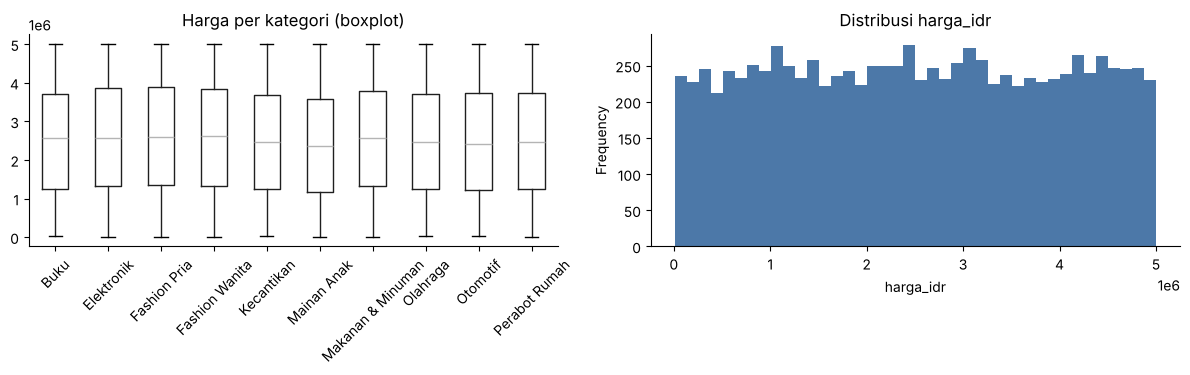

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df_bersih.boxplot(column=KOLOM_NUM, by=KOLOM_GRUP, ax=ax[0], rot=45, grid=False)
ax[0].set_title("Harga per kategori (boxplot)"); ax[0].set_xlabel(""); fig.suptitle("")
df_bersih[KOLOM_NUM].plot.hist(bins=40, ax=ax[1], color="#4c78a8")
ax[1].set_title("Distribusi harga_idr"); ax[1].set_xlabel("harga_idr")
plt.tight_layout(); plt.show()

**Hasil:** tidak ada outlier IQR pada `harga_idr` di semua kategori; sebaran harga mendekati seragam (Rp10 ribu–Rp5 juta) sehingga tidak ada ekor panjang. Kolom `kuantitas` (1–5), `rating_pembeli` (1–5) dan `diskon_pct` (0–30) semuanya di rentang valid. Jadi langkah outlier tidak mengubah data — ini temuan audit yang sah, bukan langkah yang terlewat.

**Langkah 4 — Tipe data.** `kuantitas` → integer nullable, kolom kategorikal → `category`, tanggal tetap `datetime64`.

In [11]:
df_bersih["kuantitas"] = df_bersih["kuantitas"].astype("Int64")
df_bersih["diskon_pct"] = df_bersih["diskon_pct"].astype("int64")
kolom_kategori = ["kategori_produk", "sentimen_ulasan", "metode_pembayaran", "kota_pembeli", "status_retur"]
df_bersih[kolom_kategori] = df_bersih[kolom_kategori].astype("category")
df_bersih["tanggal_pembelian"] = pd.to_datetime(df_bersih["tanggal_pembelian"])

# Kolom turunan yang dipakai analisis & model
df_bersih["total_nilai"] = df_bersih["harga_idr"] * df_bersih["kuantitas"].astype("float") * (1 - df_bersih["diskon_pct"] / 100)
df_bersih["retur"] = (df_bersih["status_retur"] == "Diretur").astype("int8")   # target: 1 = diretur
df_bersih.dtypes.to_frame("tipe")

,tipe
transaction_id,str
user_id,str
product_id,str
kategori_produk,category
nama_produk,str
harga_idr,float64
kuantitas,Int64
diskon_pct,int64
rating_pembeli,float64
sentimen_ulasan,category


### 2.4 Laporan kualitas: sebelum vs sesudah

In [12]:
laporan = pd.DataFrame({
    'sebelum': cek_kualitas(df_mentah, KOLOM_NUM, KOLOM_GRUP, KUNCI),
    'sesudah': cek_kualitas(df_bersih, KOLOM_NUM, KOLOM_GRUP, KUNCI),
})
laporan.to_csv(PATH_LAPOR)
laporan

,sebelum,sesudah
n_baris,10000,10000
n_duplikat,0,0
n_missing,2177,1792
n_outlier,0,0


**Membaca tabel:** `n_missing` turun dari 2.177 ke 1.792 sel. Sisa ini *sengaja* dipertahankan: 1.306 sel asli (numerik + tanggal + `user_id`, lihat tabel strategi di atas) ditambah 486 sel `total_nilai`, kolom turunan yang otomatis kosong bila harga/kuantitas kosong. Semuanya diselesaikan secara leakage-safe di Tahap 4 atau diabaikan di analisis yang membutuhkannya. Duplikat dan outlier bernilai 0 sebelum maupun sesudah karena memang tidak ditemukan pada dataset ini.

## 3. Analisis
Kolom turunan: `total_nilai = harga × kuantitas × (1 − diskon/100)` dan `retur` (1 = diretur). Baris dengan nilai kosong pada kolom yang dibutuhkan suatu analisis dikeluarkan hanya untuk analisis itu.

### 3.1 GroupBy lanjutan: kategori produk

In [13]:
per_kategori = (df_bersih.groupby("kategori_produk", observed=True)
    .agg(n_transaksi=("transaction_id", "size"),
         omzet_miliar=("total_nilai", lambda s: s.sum() / 1e9),
         rata_nilai_juta=("total_nilai", lambda s: s.mean() / 1e6),
         rata_rating=("rating_pembeli", "mean"),
         rata_diskon=("diskon_pct", "mean"),
         tingkat_retur=("retur", "mean"))
    .round(3).sort_values("omzet_miliar", ascending=False))
per_kategori

,n_transaksi,omzet_miliar,rata_nilai_juta,rata_rating,rata_diskon,tingkat_retur
kategori_produk,,,,,,
Fashion Pria,1025,6.672,6.871,3.044,13.000,0.220
Perabot Rumah,1037,6.535,6.621,3.043,13.197,0.222
Makanan & Minuman,974,6.354,6.774,2.988,13.332,0.227
Otomotif,1034,6.332,6.481,2.992,13.279,0.237
Fashion Wanita,971,6.250,6.793,2.995,13.265,0.230
Elektronik,996,6.239,6.533,2.986,13.559,0.217
Mainan Anak,1027,6.086,6.255,2.979,13.096,0.218
Buku,988,6.047,6.433,3.028,13.047,0.217
Olahraga,998,5.979,6.333,2.988,13.001,0.214


### 3.2 Faktor apa yang berkaitan dengan retur?

In [14]:
def retur_per(kolom, urut=None):
    t = df_bersih.groupby(kolom, observed=True)["retur"].agg(tingkat_retur="mean", n="size").round(3)
    p = chi2_contingency(pd.crosstab(df_bersih[kolom], df_bersih["retur"]))[1]
    return t if urut is None else t.loc[urut], p

hasil = []
for kol in ["kategori_produk", "metode_pembayaran", "kota_pembeli", "diskon_pct", "sentimen_ulasan"]:
    t, p = retur_per(kol)
    hasil.append({"faktor": kol, "min_retur": t.tingkat_retur.min(), "maks_retur": t.tingkat_retur.max(), "p_chi2": p})
pd.DataFrame(hasil).round(4)

,faktor,min_retur,maks_retur,p_chi2
0,kategori_produk,0.214,0.245,0.8256
1,metode_pembayaran,0.220,0.231,0.8137
2,kota_pembeli,0.204,0.242,0.7887
3,diskon_pct,0.218,0.231,0.9516
4,sentimen_ulasan,0.050,0.456,0.0000


,tingkat_retur,n
kelompok_rating,,
1-2,0.507,2476
>2-3,0.240,2390
>3-4,0.079,2404
>4-5,0.050,2193


sentimen_ulasan,Negatif,Netral,Positif,Tidak Diketahui
kategori_produk,,,,
Buku,0.455,0.125,0.054,0.262
Elektronik,0.487,0.111,0.050,0.250
Fashion Pria,0.439,0.168,0.040,0.205
Fashion Wanita,0.458,0.125,0.045,0.378
Kecantikan,0.509,0.132,0.040,0.194
Mainan Anak,0.440,0.126,0.051,0.200
Makanan & Minuman,0.459,0.137,0.048,0.286
Olahraga,0.424,0.120,0.081,0.167
Otomotif,0.448,0.176,0.043,0.292


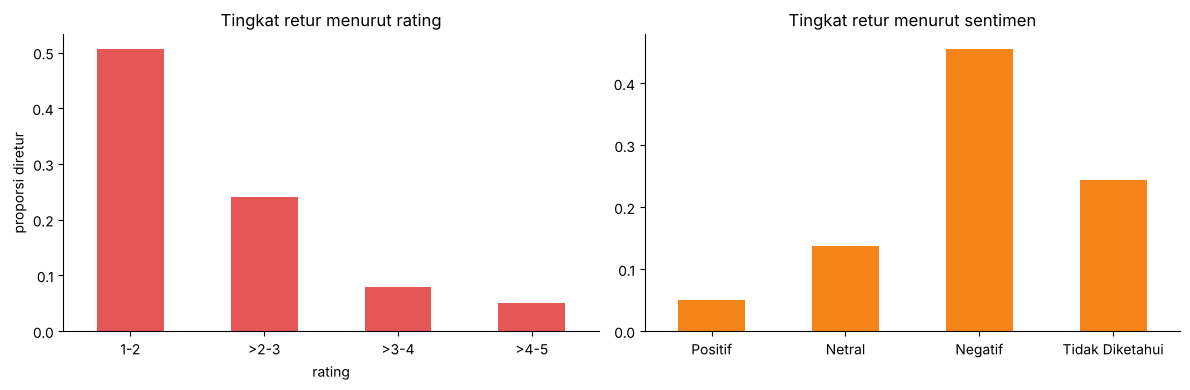

In [15]:
# Rating dikelompokkan, lalu sentimen x kategori
df_bersih["kelompok_rating"] = pd.cut(df_bersih["rating_pembeli"], [0, 2, 3, 4, 5],
                                      labels=["1-2", ">2-3", ">3-4", ">4-5"])
ret_rating = df_bersih.groupby("kelompok_rating", observed=True)["retur"].agg(tingkat_retur="mean", n="size").round(3)
display(ret_rating)

pivot = df_bersih.pivot_table(index="kategori_produk", columns="sentimen_ulasan", values="retur",
                              aggfunc="mean", observed=True).round(3)
display(pivot)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ret_rating["tingkat_retur"].plot.bar(ax=ax[0], color="#e45756", rot=0)
ax[0].set_title("Tingkat retur menurut rating"); ax[0].set_ylabel("proporsi diretur"); ax[0].set_xlabel("rating")
sent = df_bersih.groupby("sentimen_ulasan", observed=True)["retur"].mean().reindex(["Positif", "Netral", "Negatif", "Tidak Diketahui"])
sent.plot.bar(ax=ax[1], color="#f58518", rot=0)
ax[1].set_title("Tingkat retur menurut sentimen"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

In [16]:
# Seberapa besar kontribusi pengalaman buruk terhadap total retur?
retur_total = df_bersih["retur"].sum()
rating_rendah = df_bersih[df_bersih["rating_pembeli"] <= 2]
print(f"Transaksi rating <=2   : {len(rating_rendah):,} ({len(rating_rendah)/len(df_bersih):.1%} dari semua transaksi), retur {rating_rendah['retur'].mean():.1%}")
print(f"Porsi retur dari rating <=2          : {rating_rendah['retur'].sum()/retur_total:.1%} dari seluruh retur")
neg = df_bersih[df_bersih["sentimen_ulasan"] == "Negatif"]
print(f"Porsi retur dari sentimen Negatif    : {neg['retur'].sum()/retur_total:.1%} dari seluruh retur")

Transaksi rating <=2   : 2,476 (24.8% dari semua transaksi), retur 50.7%
Porsi retur dari rating <=2          : 55.9% dari seluruh retur
Porsi retur dari sentimen Negatif    : 69.1% dari seluruh retur


### 3.3 Tren waktu

,omzet_miliar,n_transaksi,tingkat_retur,pertumbuhan_omzet_%
tanggal_pembelian,,,,
2022,20.366,3127,0.231,NaN
2023,20.590,3146,0.217,1.1
2024,20.182,3066,0.223,-2.0


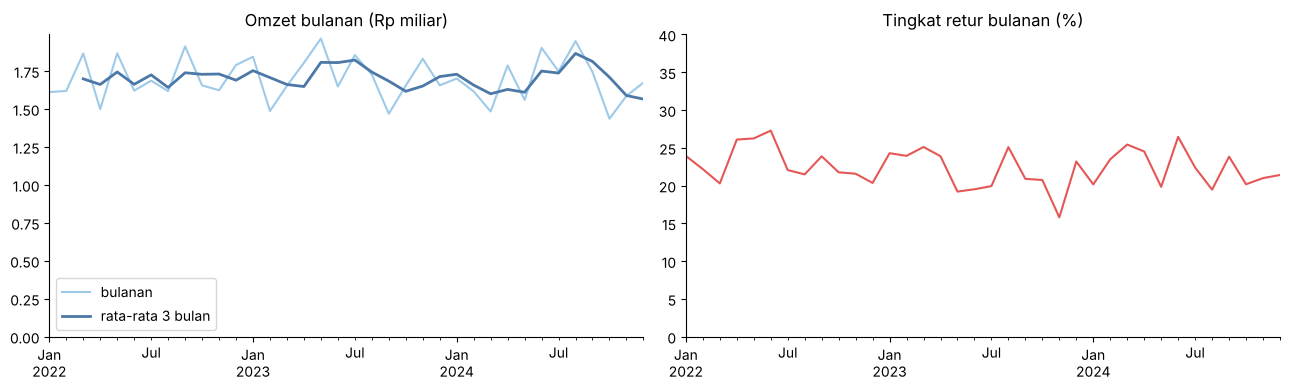

In [17]:
dt = df_bersih.dropna(subset=["tanggal_pembelian", "total_nilai"]).copy()
dt["bulan"] = dt["tanggal_pembelian"].dt.to_period("M").dt.to_timestamp()
bulanan = dt.groupby("bulan").agg(omzet_miliar=("total_nilai", lambda s: s.sum() / 1e9),
                                  n_transaksi=("transaction_id", "size"),
                                  tingkat_retur=("retur", "mean"))
bulanan["omzet_ma3"] = bulanan["omzet_miliar"].rolling(3).mean()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
bulanan["omzet_miliar"].plot(ax=ax[0], color="#9ecae9", label="bulanan")
bulanan["omzet_ma3"].plot(ax=ax[0], color="#4c78a8", lw=2, label="rata-rata 3 bulan")
ax[0].set_title("Omzet bulanan (Rp miliar)"); ax[0].set_xlabel(""); ax[0].legend(); ax[0].set_ylim(0)
(bulanan["tingkat_retur"] * 100).plot(ax=ax[1], color="#e45756")
ax[1].set_title("Tingkat retur bulanan (%)"); ax[1].set_xlabel(""); ax[1].set_ylim(0, 40)
plt.tight_layout(); plt.show()

tahunan = dt.groupby(dt["tanggal_pembelian"].dt.year).agg(omzet_miliar=("total_nilai", lambda s: s.sum() / 1e9),
                                                          n_transaksi=("transaction_id", "size"),
                                                          tingkat_retur=("retur", "mean")).round(3)
tahunan["pertumbuhan_omzet_%"] = (tahunan["omzet_miliar"].pct_change() * 100).round(1)
tahunan

In [18]:
# Musiman: rata-rata omzet per bulan kalender (apakah ada bulan yang konsisten tinggi?)
musim = dt.groupby(dt["tanggal_pembelian"].dt.month)["total_nilai"].sum().div(1e9).round(2)
musim.to_frame("omzet_miliar_3thn").T

tanggal_pembelian,1,2,3,4,5,6,7,8,9,10,11,12
omzet_miliar_3thn,5.16,4.72,5.0,5.09,5.39,5.17,5.29,5.29,5.12,4.75,5.04,5.12


### 3.4 Analisis RFM (pelanggan × transaksi)
Hanya transaksi dengan `user_id`, `tanggal_pembelian`, dan `total_nilai` terisi yang dipakai. Tanggal acuan = hari setelah transaksi terakhir. **Recency** = hari sejak transaksi terakhir, **Frequency** = jumlah transaksi, **Monetary** = total nilai belanja. Skor 1–5 memakai kuintil (`rank(method="first")` agar nilai kembar tidak membuat `qcut` gagal).

In [19]:
r = df_bersih.dropna(subset=["user_id", "tanggal_pembelian", "total_nilai"])
acuan = r["tanggal_pembelian"].max() + pd.Timedelta(days=1)
rfm = r.groupby("user_id").agg(recency=("tanggal_pembelian", lambda s: (acuan - s.max()).days),
                               frequency=("transaction_id", "nunique"),
                               monetary=("total_nilai", "sum"))

rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"),   5, labels=[5, 4, 3, 2, 1]).astype(int)  # baru = skor tinggi
rfm["F"] = pd.qcut(rfm["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"),  5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["segmen"] = np.select(
    [(rfm.R >= 4) & (rfm.F >= 4) & (rfm.M >= 4),
     (rfm.F >= 4) & (rfm.R >= 3),
     (rfm.R <= 2) & (rfm.F >= 3),
     (rfm.R >= 4) & (rfm.F <= 2),
     (rfm.R <= 2) & (rfm.F <= 2)],
    ["Champions", "Setia", "Berisiko hilang", "Pelanggan baru", "Hibernasi"],
    default="Potensial")

seg = (rfm.groupby("segmen").agg(n_pelanggan=("monetary", "size"),
                                 rata_recency_hari=("recency", "mean"),
                                 rata_frekuensi=("frequency", "mean"),
                                 total_monetary_miliar=("monetary", lambda s: s.sum() / 1e9))
       .assign(porsi_pelanggan_pct=lambda d: d.n_pelanggan / d.n_pelanggan.sum() * 100,
               porsi_omzet_pct=lambda d: d.total_monetary_miliar / d.total_monetary_miliar.sum() * 100)
       .round(2).sort_values("total_monetary_miliar", ascending=False))
print("Pelanggan dianalisis:", len(rfm), "| tanggal acuan:", acuan.date())
seg

Pelanggan dianalisis: 2871 | tanggal acuan: 2025-01-01


,n_pelanggan,rata_recency_hari,rata_frekuensi,total_monetary_miliar,porsi_pelanggan_pct,porsi_omzet_pct
segmen,,,,,,
Champions,467,79.57,5.30,18.11,16.27,29.88
Berisiko hilang,479,482.55,3.82,11.99,16.68,19.77
Setia,417,169.85,4.66,10.95,14.52,18.06
Potensial,546,175.43,2.57,9.23,19.02,15.22
Hibernasi,669,629.98,1.58,6.83,23.30,11.27
Pelanggan baru,293,86.66,1.89,3.52,10.21,5.80


20% pelanggan teratas menyumbang 41.4% omzet
Pelanggan dengan 1 transaksi : 15.4%
Pelanggan dengan >=5 transaksi: 20.4%


,tingkat_retur,n_transaksi
grup_frekuensi,,
1-2 transaksi,0.223,1705
3-4 transaksi,0.225,4186
5+ transaksi,0.224,3368


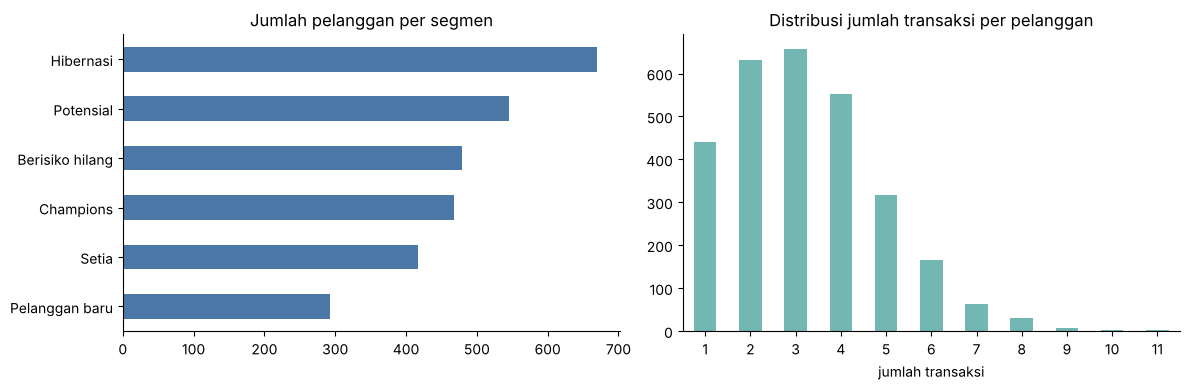

In [20]:
# Konsentrasi omzet (Pareto) dan distribusi frekuensi pembelian
urut = rfm["monetary"].sort_values(ascending=False)
top20 = urut.head(int(len(urut) * .2)).sum() / urut.sum()
print(f"20% pelanggan teratas menyumbang {top20:.1%} omzet")
print("Pelanggan dengan 1 transaksi :", f"{(rfm.frequency == 1).mean():.1%}")
print("Pelanggan dengan >=5 transaksi:", f"{(rfm.frequency >= 5).mean():.1%}")

# Apakah pelanggan frekuensi tinggi berbeda tingkat returnya?
rr = r.merge(rfm[["frequency"]], left_on="user_id", right_index=True)
rr["grup_frekuensi"] = pd.cut(rr["frequency"], [0, 2, 4, 20], labels=["1-2 transaksi", "3-4 transaksi", "5+ transaksi"])
display(rr.groupby("grup_frekuensi", observed=True)["retur"].agg(tingkat_retur="mean", n_transaksi="size").round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
seg["n_pelanggan"].sort_values().plot.barh(ax=ax[0], color="#4c78a8"); ax[0].set_title("Jumlah pelanggan per segmen"); ax[0].set_ylabel("")
rfm["frequency"].value_counts().sort_index().plot.bar(ax=ax[1], color="#72b7b2", rot=0)
ax[1].set_title("Distribusi jumlah transaksi per pelanggan"); ax[1].set_xlabel("jumlah transaksi")
plt.tight_layout(); plt.show()

## Tiga temuan yang bisa ditindaklanjuti

**Temuan 1 — Retur ditentukan oleh pengalaman pembeli, bukan oleh atribut transaksi.**
Transaksi dengan rating ≤ 2 diretur **50,7%**, sedangkan rating > 4 hanya **5,0%**; ulasan *Negatif* diretur 45,6% vs *Positif* 5,0%. Transaksi rating ≤ 2 hanya 24,8% dari seluruh transaksi tetapi menyumbang **55,9%** dari seluruh retur; ulasan Negatif menyumbang 69,1%.
*Tindakan:* buat alur otomatis — rating ≤ 2 atau ulasan negatif memicu tindak lanjut CS dalam 24 jam (penggantian, kompensasi, panduan penggunaan) sebelum pembeli mengajukan retur; tinjau produk/penjual dengan rating rendah berulang.

**Temuan 2 — Kategori, metode bayar, kota, dan diskon tidak memengaruhi retur, jadi tidak perlu kebijakan retur khusus per segmen.**
Tingkat retur seragam di kisaran 20–25% pada semua kategori, metode pembayaran, kota, dan level diskon (uji chi-kuadrat, semua p > 0,78; Kecantikan 24,5% terlihat tertinggi tetapi tidak signifikan). Model sederhana yang hanya memakai fitur saat checkout hanya mencapai ROC-AUC ≈ 0,55 (hampir acak).
*Tindakan:* diskon hingga 30% aman dari sisi retur — pertimbangannya cukup margin dan volume. Pencegahan retur sebaiknya difokuskan pada kualitas pasca-pembelian (Temuan 1), bukan memblokir kategori/kota/metode tertentu.

**Temuan 3 — Omzet stagnan dan basis pelanggan bernilai sedang menuju hilang.**
Omzet ±Rp20 miliar per tahun, pertumbuhan hanya +1,1% (2023) lalu −2,0% (2024), tanpa pola musiman yang jelas (bulanan ≈ Rp4,7–5,4 miliar per bulan kalender). Berdasarkan RFM, 20% pelanggan teratas menyumbang 41,4% omzet, dan segmen **Berisiko hilang** (479 pelanggan, rata-rata 3,8 transaksi, tetapi sudah ±480 hari tidak belanja) memegang **19,8% omzet (±Rp12 miliar)**. Sementara itu 15,4% pelanggan hanya sekali beli dan segmen pelanggan baru hanya 10%.
*Tindakan:* jalankan kampanye *win-back* (voucher personal, pengingat) ke segmen Berisiko hilang, program loyalitas untuk Champions/Setia, dan ajakan pembelian kedua bagi pelanggan sekali beli. Ukur lewat uplift reaktivasi segmen tersebut.

> *Catatan kehati-hatian:* data ini tampak sintetis (harga hampir seragam, kolom nama produk tidak konsisten per `product_id`), sehingga yang paling dapat dipercaya adalah pola yang kuat (Temuan 1); Temuan 2 dan 3 adalah "tidak ada perbedaan" dan angka agregat, bukan klaim kausal.

## 4. Persiapan model
**Target:** `retur` (klasifikasi biner; ±22% positif → tidak seimbang → `stratify=y`).

**Fitur:** `kategori_produk`, `metode_pembayaran`, `kota_pembeli`, `sentimen_ulasan` (kategorikal); `harga_idr`, `kuantitas`, `diskon_pct`, `rating_pembeli`, `bulan_beli`, `hari_minggu` (numerik).

**Dikeluarkan:** `transaction_id`, `user_id`, `product_id` (pengenal, tidak punya makna prediktif umum), `nama_produk` (30 nama berbeda per `product_id` — tidak konsisten), `tanggal_pembelian` (diganti `bulan_beli` & `hari_minggu`), `total_nilai` (turunan langsung dari fitur lain), `status_retur` (target itu sendiri).

**Urutan anti-leakage:** split dulu → `fit` imputer/scaler/encoder **hanya pada train** → `transform` train & test.

In [21]:
df_bersih["bulan_beli"]  = df_bersih["tanggal_pembelian"].dt.month.astype("float")      # NaN bila tanggal kosong
df_bersih["hari_minggu"] = df_bersih["tanggal_pembelian"].dt.dayofweek.astype("float")

fitur_num = ["harga_idr", "kuantitas", "diskon_pct", "rating_pembeli", "bulan_beli", "hari_minggu"]
fitur_cat = ["kategori_produk", "metode_pembayaran", "kota_pembeli", "sentimen_ulasan"]

X = df_bersih[fitur_num + fitur_cat].copy()
X["kuantitas"] = X["kuantitas"].astype("float")          # Int64 nullable -> float agar kompatibel dengan sklearn
X[fitur_cat] = X[fitur_cat].astype(str)
y = df_bersih["retur"]

# 1) SPLIT DULU, dengan stratifikasi pada target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "| test:", X_test.shape)
print("proporsi retur  -> train: %.4f | test: %.4f | total: %.4f" % (y_train.mean(), y_test.mean(), y.mean()))

train: (8000, 10) | test: (2000, 10)
proporsi retur  -> train: 0.2246 | test: 0.2245 | total: 0.2246


In [22]:
# 2) ColumnTransformer: imputasi + scaling (numerik), imputasi + one-hot (kategorikal)
pra_num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),
                    ("scaler", StandardScaler())])
pra_cat = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Tidak Diketahui")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
prapemroses = ColumnTransformer([("num", pra_num, fitur_num), ("cat", pra_cat, fitur_cat)])

# 3) fit HANYA pada train; test hanya di-transform
X_train_t = prapemroses.fit_transform(X_train)
X_test_t  = prapemroses.transform(X_test)

nama_fitur = prapemroses.get_feature_names_out()
print("matriks train:", X_train_t.shape, "| matriks test:", X_test_t.shape)
print("NaN tersisa  -> train:", int(np.isnan(X_train_t).sum()), "| test:", int(np.isnan(X_test_t).sum()))

# Bukti tidak ada leakage: statistik imputer berasal dari train, bukan dari seluruh data
med_train = pd.Series(prapemroses.named_transformers_["num"]["imputer"].statistics_, index=fitur_num)
med_all   = X[fitur_num].median()
pd.DataFrame({"median_train (dipakai)": med_train, "median_seluruh_data (tidak dipakai)": med_all}).round(3)

matriks train: (8000, 40) | matriks test: (2000, 40)
NaN tersisa  -> train: 0 | test: 0


,median_train (dipakai),median_seluruh_data (tidak dipakai)
harga_idr,2507018.0,2499292.0
kuantitas,3.0,3.0
diskon_pct,15.0,15.0
rating_pembeli,3.0,3.0
bulan_beli,7.0,7.0
hari_minggu,3.0,3.0


### Uji kewajaran (baseline) & catatan leakage konseptual
Pipeline di atas bebas *leakage teknis*. Ada pula *leakage konseptual*: `rating_pembeli` dan `sentimen_ulasan` baru ada **setelah** barang diterima, mendekati waktu keputusan retur, sehingga tidak tersedia bila model dipakai untuk memprediksi saat checkout. Dua skenario dibandingkan dengan regresi logistik sederhana (`class_weight="balanced"`).

In [23]:
def baseline(num, cat):
    pre = ColumnTransformer([("num", pra_num, num), ("cat", pra_cat, cat)])
    model = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))])
    model.fit(X_train[num + cat], y_train)
    p = model.predict_proba(X_test[num + cat])[:, 1]
    return {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)}

hasil = pd.DataFrame({
    "A. Semua fitur (termasuk rating & sentimen)": baseline(fitur_num, fitur_cat),
    "B. Fitur saat checkout (tanpa rating & sentimen)": baseline(
        [f for f in fitur_num if f != "rating_pembeli"], [f for f in fitur_cat if f != "sentimen_ulasan"]),
}).T.round(3)
hasil["acuan PR-AUC acak"] = round(y_test.mean(), 3)
hasil

,ROC-AUC,PR-AUC,acuan PR-AUC acak
A. Semua fitur (termasuk rating & sentimen),0.793,0.502,0.224
B. Fitur saat checkout (tanpa rating & sentimen),0.552,0.261,0.224


Skenario A jauh lebih kuat karena rating/sentimen sangat berkaitan dengan retur; skenario B mendekati tebakan acak karena fitur transaksi lain memang tidak berkaitan dengan retur (konsisten dengan Tahap 3). Pilih skenario sesuai kapan prediksi akan dipakai.

### Simpan data bersih dan kamus data

In [24]:
kolom_simpan = ["transaction_id", "user_id", "product_id", "kategori_produk", "nama_produk", "harga_idr", "kuantitas",
                "diskon_pct", "rating_pembeli", "sentimen_ulasan", "tanggal_pembelian", "metode_pembayaran",
                "kota_pembeli", "status_retur", "total_nilai", "retur"]
data_simpan = df_bersih[kolom_simpan]
data_simpan.to_csv(PATH_BERSIH, index=False)

keterangan = {
    "transaction_id": "ID transaksi (kunci unik)", "user_id": "ID pembeli (kosong dibiarkan NaN)", "product_id": "ID produk",
    "kategori_produk": "Kategori produk", "nama_produk": "Nama produk (kosong -> 'Tidak Diketahui'; tidak konsisten per product_id)",
    "harga_idr": "Harga satuan (Rp), outlier IQR per kategori di-cap (tidak ada yang kena)", "kuantitas": "Jumlah barang (1-5)",
    "diskon_pct": "Diskon (%)", "rating_pembeli": "Rating 1-5 (kosong dibiarkan NaN, diimputasi setelah split)",
    "sentimen_ulasan": "Sentimen ulasan, label sudah dinormalkan; kosong -> 'Tidak Diketahui'",
    "tanggal_pembelian": "Tanggal transaksi (kosong dibiarkan NaT)", "metode_pembayaran": "Metode pembayaran",
    "kota_pembeli": "Kota pembeli (kosong -> 'Tidak Diketahui')", "status_retur": "Status retur (Diretur / Tidak Diretur)",
    "total_nilai": "Turunan: harga x kuantitas x (1 - diskon/100)", "retur": "Turunan: target biner, 1 = Diretur",
}
kamus = pd.DataFrame({
    "kolom": kolom_simpan,
    "tipe": [str(data_simpan[k].dtype) for k in kolom_simpan],
    "n_missing": [int(data_simpan[k].isnull().sum()) for k in kolom_simpan],
    "n_unik": [int(data_simpan[k].nunique()) for k in kolom_simpan],
    "keterangan": [keterangan[k] for k in kolom_simpan],
})
kamus.to_csv(PATH_KAMUS, index=False)
kamus

,kolom,tipe,n_missing,n_unik,keterangan
0,transaction_id,str,0,10000,ID transaksi (kunci unik)
1,user_id,str,89,2893,ID pembeli (kosong dibiarkan NaN)
2,product_id,str,0,500,ID produk
3,kategori_produk,category,0,10,Kategori produk
4,nama_produk,str,0,100,Nama produk (kosong -> 'Tidak Diketahui'; tidak konsisten per product_id)
5,harga_idr,float64,298,9692,"Harga satuan (Rp), outlier IQR per kategori di-cap (tidak ada yang kena)"
6,kuantitas,Int64,195,5,Jumlah barang (1-5)
7,diskon_pct,int64,0,7,Diskon (%)
8,rating_pembeli,float64,537,41,"Rating 1-5 (kosong dibiarkan NaN, diimputasi setelah split)"
9,sentimen_ulasan,category,0,4,"Sentimen ulasan, label sudah dinormalkan; kosong -> 'Tidak Diketahui'"


## 5. Pemeriksaan akhir & reproduksibilitas
- Sel berurutan dan dapat dijalankan dari atas ke bawah (*Restart & Run All*); satu-satunya sumber acak adalah `SEED = 42` pada split dan model.
- Data mentah hanya dibaca; semua transformasi lewat kode.
- Keluaran: `output/data_bersih.csv`, `output/kamus_data.csv`, `laporan_kualitas.csv`.

In [25]:
import os
for p in [PATH_DATA, PATH_BERSIH, PATH_KAMUS, PATH_LAPOR]:
    print(f"{p:35s} ada={os.path.exists(p)}  ukuran={os.path.getsize(p):,} byte")

cek = pd.read_csv(PATH_BERSIH, parse_dates=["tanggal_pembelian"])
assert cek.shape[0] == df_bersih.shape[0] and cek["transaction_id"].is_unique
assert set(y_train.index).isdisjoint(y_test.index)           # tidak ada baris yang bocor antara train & test
print("\nCek lulus: baris konsisten, ID unik, train/test terpisah.")

data/case3_ecommerce_transactions.csv ada=True  ukuran=1,205,525 byte
output/data_bersih.csv              ada=True  ukuran=1,330,262 byte
output/kamus_data.csv               ada=True  ukuran=1,082 byte
laporan_kualitas.csv                ada=True  ukuran=86 byte

Cek lulus: baris konsisten, ID unik, train/test terpisah.
